In [1]:

# Phase 2: Build a Neural Network Engine from Scratch

## Objective

Build a small neural network library using Python and NumPy without relying on deep learning frameworks such as PyTorch or TensorFlow.

We will implement:
1. Linear layers
2. Activation functions
3. Loss functions
4. Forward and backward propagation
5. Gradient descent

## Network Architecture

Our initial network has:
- 2 input features
- 2 hidden neurons
- 1 output neuron
- Sigmoid activation in the hidden layer
- Mean Squared Error loss

We will compare our implementation with the manual calculations from Phase 1.


SyntaxError: invalid syntax (3789787683.py, line 5)

In [2]:
import numpy as np

np.set_printoptions(precision=6, suppress=True)

In [3]:
# Input data
X = np.array([[1.0, 0.0]])

# Weight matrix
W = np.array([
    [0.1, -0.1],
    [0.2,  0.1]
])

# Bias
b = np.array([[0.1, 0.0]])

print("Input shape:", X.shape)
print("Weight shape:", W.shape)
print("Bias shape:", b.shape)

Input shape: (1, 2)
Weight shape: (2, 2)
Bias shape: (1, 2)


In [ ]:
### Step 1: Implement the Linear Layer

The Linear layer performs a matrix multiplication between the input and weights, then adds the bias.

Formula:

Z = XW + b

We will create a reusable Linear class that supports different input and output sizes.

In [63]:
class Linear:
    def __init__(self, input_size, output_size):
        self.weights = np.random.randn(input_size, output_size) * 0.01
        self.bias = np.zeros((1, output_size))

    def forward(self, X):
        self.X = X
        Z = X @ self.weights + self.bias
        return Z

    def backward(self, gradient):
        self.dweights = self.X.T @ gradient
        self.dbias = np.sum(gradient, axis=0, keepdims=True)

        input_gradient = gradient @ self.weights.T

        return input_gradient

In [64]:
# Create a Linear layer with 2 inputs and 2 neurons
layer = Linear(input_size=2, output_size=2)

# Replace random weights with our Phase 1 weights
layer.weights = W.copy()
layer.bias = b.copy()

# Perform forward propagation
Z = layer.forward(X)

print("Linear layer output:")
print(Z)

Linear layer output:
[[ 0.2 -0.1]]


In [65]:
expected_output = np.array([[0.2, -0.1]])

assert np.allclose(Z, expected_output), "Test failed!"

print("Forward pass test successful!")

Forward pass test successful!


In [66]:
class Sigmoid:

    def __init__(self):
        self.output = None

    def forward(self, x):

        self.output = 1 / (1 + np.exp(-x))

        return self.output

    def backward(self, upstream_grad):

        sigmoid_derivative = self.output * (1 - self.output)

        return upstream_grad * sigmoid_derivative

In [67]:
sigmoid = Sigmoid()

In [68]:
Z = layer.forward(X)

In [69]:
H = sigmoid.forward(Z)

print("Sigmoid output:")
print(H)

Sigmoid output:
[[0.549834 0.475021]]


In [70]:
upstream_grad = np.array([[0.1019676, -0.0679784]])

dZ = sigmoid.backward(upstream_grad)

print("Sigmoid backward output:")
print(dZ)

Sigmoid backward output:
[[ 0.025239 -0.016952]]


In [71]:
class ReLU:

    def __init__(self):
        self.input = None

    def forward(self, x):

        self.input = x

        return np.maximum(0, x)

    def backward(self, upstream_grad):

        relu_derivative = (self.input > 0).astype(float)

        return upstream_grad * relu_derivative

In [72]:
relu = ReLU()

X_test = np.array([[-2, 3, 0, 5]])

output = relu.forward(X_test)

print("ReLU forward output:")
print(output)

ReLU forward output:
[[0 3 0 5]]


In [73]:
upstream_grad = np.array([[1, 2, 3, 4]])

dx = relu.backward(upstream_grad)

print("ReLU backward output:")
print(dx)

ReLU backward output:
[[0. 2. 0. 4.]]


In [74]:
class Tanh:

    def __init__(self):
        self.output = None

    def forward(self, x):

        self.output = np.tanh(x)

        return self.output

    def backward(self, upstream_grad):

        tanh_derivative = 1 - self.output ** 2

        return upstream_grad * tanh_derivative

In [75]:
tanh = Tanh()

X_test = np.array([[-2, -1, 0, 1, 2]])

output = tanh.forward(X_test)

print("Tanh forward output:")
print(output)

Tanh forward output:
[[-0.964028 -0.761594  0.        0.761594  0.964028]]


In [76]:
expected_output = np.array([
    [-0.964028, -0.761594, 0, 0.761594, 0.964028]
])

assert np.allclose(output, expected_output, atol=1e-6)

print("Tanh forward pass successful!")

Tanh forward pass successful!


In [77]:
upstream_grad = np.array([[1, 2, 3, 4, 5]])

dx = tanh.backward(upstream_grad)

print("Tanh backward output:")
print(dx)

Tanh backward output:
[[0.070651 0.839949 3.       1.679897 0.353254]]


In [78]:
class MSELoss:

    def __init__(self):
        self.prediction = None
        self.target = None

    def forward(self, prediction, target):

        self.prediction = prediction
        self.target = target

        loss = np.mean((prediction - target) ** 2)

        return loss

    def backward(self):

        N = self.prediction.size

        gradient = (2 / N) * (self.prediction - self.target)

        return gradient

In [79]:
mse = MSELoss()

prediction = np.array([[0.169946]])
target = np.array([[0.0]])

loss = mse.forward(prediction, target)

print("MSE Loss:")
print(loss)

gradient = mse.backward()

print("\nMSE Gradient:")
print(gradient)

MSE Loss:
0.028881642916000004

MSE Gradient:
[[0.339892]]


In [80]:
assert np.isclose(loss, 0.02888166, atol=1e-6)
assert np.allclose(gradient, [[0.339892]], atol=1e-6)

print("MSE forward and backward tests successful!")

MSE forward and backward tests successful!


In [81]:
class BCELoss:

    def __init__(self):
        self.prediction = None
        self.target = None

    def forward(self, prediction, target):

        self.prediction = np.clip(prediction, 1e-12, 1 - 1e-12)
        self.target = target

        loss = -np.mean(
            target * np.log(self.prediction)
            + (1 - target) * np.log(1 - self.prediction)
        )

        return loss

    def backward(self):

        N = self.prediction.size

        gradient = (1 / N) * (
            -self.target / self.prediction
            + (1 - self.target) / (1 - self.prediction)
        )

        return gradient

In [82]:
bce = BCELoss()

prediction = np.array([[0.9, 0.2]])
target = np.array([[1.0, 0.0]])

loss = bce.forward(prediction, target)

print("BCE Loss:")
print(loss)

gradient = bce.backward()

print("\nBCE Gradient:")
print(gradient)

BCE Loss:
0.164252033486018

BCE Gradient:
[[-0.555556  0.625   ]]


In [83]:
assert np.isclose(loss, 0.164252, atol=1e-6)
assert np.allclose(gradient, [[-0.555556, 0.625]], atol=1e-6)

print("BCE forward and backward tests successful!")

BCE forward and backward tests successful!


In [84]:
class Network:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, X):
        output = X

        for layer in self.layers:
            output = layer.forward(output)

        return output
        
    def backward(self, gradient):
        for layer in reversed(self.layers):
            gradient = layer.backward(gradient)

        return gradient

In [85]:
network = Network([
    Linear(input_size=2, output_size=2),
    Sigmoid(),
    Linear(input_size=2, output_size=1)
])

In [86]:
# Hidden layer
network.layers[0].weights = W.copy()
network.layers[0].bias = b.copy()

# Output layer
network.layers[2].weights = np.array([[0.3], [-0.2]])
network.layers[2].bias = np.array([[0.1]])

In [87]:
prediction = network.forward(X)

print("Network prediction:")
print(prediction)

Network prediction:
[[0.169946]]


In [88]:
mse = MSELoss()

target = np.array([[0.0]])

loss = mse.forward(prediction, target)
gradient = mse.backward()

print("Loss:", loss)
print("Initial gradient:", gradient)

Loss: 0.028881655386479542
Initial gradient: [[0.339892]]


In [89]:
input_gradient = network.backward(gradient)

print("Gradient with respect to input:")
print(input_gradient)

Gradient with respect to input:
[[0.004219 0.003353]]


In [90]:
print("Hidden layer weight gradients:")
print(network.layers[0].dweights)

print("Hidden layer bias gradients:")
print(network.layers[0].dbias)

print("Output layer weight gradients:")
print(network.layers[2].dweights)

print("Output layer bias gradients:")
print(network.layers[2].dbias)

Hidden layer weight gradients:
[[ 0.025239 -0.016952]
 [ 0.        0.      ]]
Hidden layer bias gradients:
[[ 0.025239 -0.016952]]
Output layer weight gradients:
[[0.186884]
 [0.161456]]
Output layer bias gradients:
[[0.339892]]


In [91]:
epsilon = 1e-5

# Select the first weight in the hidden Linear layer
layer = network.layers[0]

# Save its original value
original_weight = layer.weights[0, 0]

# Calculate loss with weight + epsilon
layer.weights[0, 0] = original_weight + epsilon
prediction_plus = network.forward(X)
loss_plus = mse.forward(prediction_plus, target)

# Calculate loss with weight - epsilon
layer.weights[0, 0] = original_weight - epsilon
prediction_minus = network.forward(X)
loss_minus = mse.forward(prediction_minus, target)

# Restore original weight
layer.weights[0, 0] = original_weight

# Numerical gradient
numerical_gradient = (loss_plus - loss_minus) / (2 * epsilon)

print("Analytical gradient:", layer.dweights[0, 0])
print("Numerical gradient:", numerical_gradient)

Analytical gradient: 0.025238676328414086
Numerical gradient: 0.025238676328205586


In [92]:
relative_error = abs(
    numerical_gradient - layer.dweights[0, 0]
) / max(
    abs(numerical_gradient),
    abs(layer.dweights[0, 0])
)

print("Relative error:", relative_error)

if relative_error < 1e-6:
    print("Gradient check PASSED!")
else:
    print("Gradient check FAILED!")

Relative error: 8.261125952547364e-12
Gradient check PASSED!


In [93]:
def gradient_check(network, X, target, loss_fn, epsilon=1e-5):

    # First calculate analytical gradients
    prediction = network.forward(X)
    loss = loss_fn.forward(prediction, target)
    gradient = loss_fn.backward()

    network.backward(gradient)

    analytical_gradients = []

    # Save analytical gradients
    for layer in network.layers:
        if isinstance(layer, Linear):
            analytical_gradients.append({
                "weights": layer.dweights.copy(),
                "bias": layer.dbias.copy()
            })

    numerical_gradients = []

    # Calculate numerical gradients
    for layer in network.layers:

        if not isinstance(layer, Linear):
            continue

        numerical = {"weights": np.zeros_like(layer.weights),
                     "bias": np.zeros_like(layer.bias)}

        # Check every weight
        for index in np.ndindex(layer.weights.shape):

            original = layer.weights[index]

            layer.weights[index] = original + epsilon
            loss_plus = loss_fn.forward(
                network.forward(X), target
            )

            layer.weights[index] = original - epsilon
            loss_minus = loss_fn.forward(
                network.forward(X), target
            )

            layer.weights[index] = original

            numerical["weights"][index] = (
                loss_plus - loss_minus
            ) / (2 * epsilon)

        # Check every bias
        for index in np.ndindex(layer.bias.shape):

            original = layer.bias[index]

            layer.bias[index] = original + epsilon
            loss_plus = loss_fn.forward(
                network.forward(X), target
            )

            layer.bias[index] = original - epsilon
            loss_minus = loss_fn.forward(
                network.forward(X), target
            )

            layer.bias[index] = original

            numerical["bias"][index] = (
                loss_plus - loss_minus
            ) / (2 * epsilon)

        numerical_gradients.append(numerical)

    # Compare analytical and numerical gradients
    errors = []

    for analytical, numerical in zip(
        analytical_gradients, numerical_gradients
    ):

        for parameter in ["weights", "bias"]:

            a = analytical[parameter]
            n = numerical[parameter]

            relative_error = np.abs(a - n) / np.maximum(
                1e-12, np.maximum(np.abs(a), np.abs(n))
            )

            errors.extend(relative_error.flatten())

    max_error = np.max(errors)

    print("Maximum relative error:", max_error)

    if max_error < 1e-6:
        print("GRADIENT CHECK PASSED!")
    else:
        print("GRADIENT CHECK FAILED!")

    return max_error

In [94]:
gradient_check(network, X, target, mse)

Maximum relative error: 2.195886714444346e-11
GRADIENT CHECK PASSED!


np.float64(2.195886714444346e-11)

In [95]:
import numpy as np
import matplotlib.pyplot as plt

In [96]:
# Number of points in each moon
n_samples = 200

# Generate random angles between 0 and pi
theta = np.random.uniform(0, np.pi, n_samples)

# Generate the first moon
moon1_x = np.cos(theta)
moon1_y = np.sin(theta)

# Combine x and y coordinates
moon1 = np.column_stack((moon1_x, moon1_y))

print("First moon shape:", moon1.shape)
print(moon1[:5])

First moon shape: (200, 2)
[[ 0.914577  0.404412]
 [ 0.831994  0.554785]
 [ 0.911428  0.411459]
 [ 0.999289  0.037697]
 [-0.941946  0.335764]]


In [97]:
# Generate another 200 random angles
theta = np.random.uniform(0, np.pi, n_samples)

# Generate the second moon
moon2_x = 1 - np.cos(theta)
moon2_y = 0.5 - np.sin(theta)

# Combine coordinates
moon2 = np.column_stack((moon2_x, moon2_y))

print("Second moon shape:", moon2.shape)
print(moon2[:5])

Second moon shape: (200, 2)
[[ 0.945397 -0.498508]
 [ 0.400166 -0.300124]
 [ 0.755521 -0.469655]
 [ 1.029355 -0.499569]
 [ 1.887631  0.039444]]


In [98]:
moon2_x = 1 - np.cos(theta)
moon2_y = 0.5 - np.sin(theta)

In [99]:
noise = 0.12

moon1 += np.random.randn(n_samples, 2) * noise
moon2 += np.random.randn(n_samples, 2) * noise

In [100]:
# First moon belongs to class 0
y1 = np.zeros((n_samples, 1))

# Second moon belongs to class 1
y2 = np.ones((n_samples, 1))

print("First labels shape:", y1.shape)
print("Second labels shape:", y2.shape)

First labels shape: (200, 1)
Second labels shape: (200, 1)


In [101]:
# Combine both moons
X = np.vstack((moon1, moon2))

# Combine their labels
y = np.vstack((y1, y2))

# Shuffle the dataset
indices = np.random.permutation(len(X))

X = X[indices]
y = y[indices]

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("First five samples:")
print(X[:5])

print("First five labels:")
print(y[:5])

Dataset shape: (400, 2)
Labels shape: (400, 1)
First five samples:
[[ 1.645759 -0.337993]
 [ 0.81127  -0.487362]
 [ 0.807224 -0.57888 ]
 [ 1.035342  0.262375]
 [ 0.022205  0.575654]]
First five labels:
[[1.]
 [1.]
 [1.]
 [0.]
 [1.]]


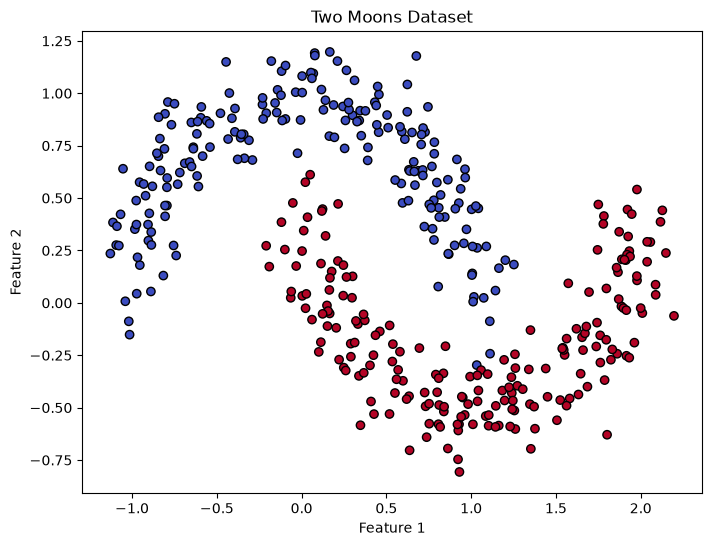

In [102]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y.ravel(),
    cmap="coolwarm",
    edgecolors="black"
)

plt.title("Two Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [103]:
# Calculate how many samples will be used for training
train_size = int(0.8 * len(X))

print("Training samples:", train_size)
print("Testing samples:", len(X) - train_size)

Training samples: 320
Testing samples: 80


In [104]:
# Generate shuffled indices
indices = np.random.permutation(len(X))

# Split indices into training and testing
train_indices = indices[:train_size]
test_indices = indices[train_size:]

# Create training data
X_train = X[train_indices]
y_train = y[train_indices]

# Create testing data
X_test = X[test_indices]
y_test = y[test_indices]

In [105]:
# Generate shuffled indices
indices = np.random.permutation(len(X))

# Split indices into training and testing
train_indices = indices[:train_size]
test_indices = indices[train_size:]

# Create training data
X_train = X[train_indices]
y_train = y[train_indices]

# Create testing data
X_test = X[test_indices]
y_test = y[test_indices]

In [106]:
print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing data shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (320, 2)
Training labels shape: (320, 1)
Testing data shape: (80, 2)
Testing labels shape: (80, 1)


In [107]:
print("Training class distribution:")
print("Class 0:", np.sum(y_train == 0))
print("Class 1:", np.sum(y_train == 1))

print("\nTesting class distribution:")
print("Class 0:", np.sum(y_test == 0))
print("Class 1:", np.sum(y_test == 1))

Training class distribution:
Class 0: 150
Class 1: 170

Testing class distribution:
Class 0: 50
Class 1: 30


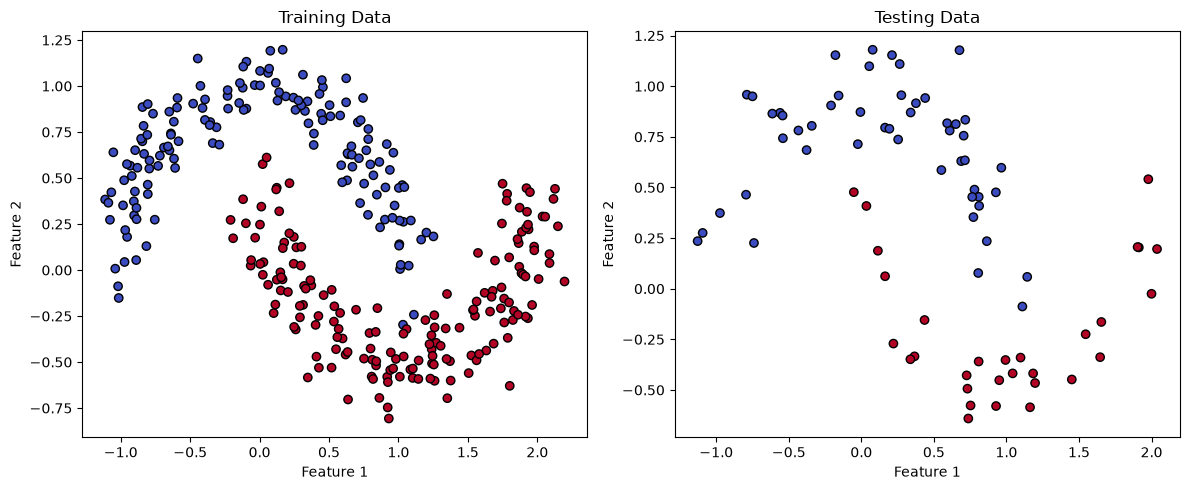

In [108]:
plt.figure(figsize=(12, 5))

# Training data
plt.subplot(1, 2, 1)
plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train.ravel(),
    cmap="coolwarm",
    edgecolors="black"
)
plt.title("Training Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# Testing data
plt.subplot(1, 2, 2)
plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test.ravel(),
    cmap="coolwarm",
    edgecolors="black"
)
plt.title("Testing Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.tight_layout()
plt.show()

In [109]:
# Create the neural network architecture

network = Network([
    Linear(2, 16),
    ReLU(),
    Linear(16, 1),
    Sigmoid()
])

print("Network architecture created successfully!")

Network architecture created successfully!


In [111]:
# Set learning rate
learning_rate = 0.01

# Create loss function
loss_function = MSELoss()

# 1. Forward pass
predictions = network.forward(X_train)

# 2. Calculate loss
loss = loss_function.forward(predictions, y_train)

# 3. Backward pass
gradient = loss_function.backward()

network.backward(gradient)

# 4. Update weights and biases
for layer in network.layers:
    if isinstance(layer, Linear):
        layer.weights -= learning_rate * layer.dweights
        layer.bias -= learning_rate * layer.dbias

print("Initial training loss:", loss)
print("One training iteration completed!")

Initial training loss: 0.25002943244374987
One training iteration completed!


In [112]:
# Training configuration
epochs = 1000
learning_rate = 0.01

# Store loss values
loss_history = []

# Create loss function
loss_function = MSELoss()

# Training loop
for epoch in range(epochs):

    # 1. Forward pass
    predictions = network.forward(X_train)

    # 2. Calculate loss
    loss = loss_function.forward(predictions, y_train)

    # 3. Backward pass
    gradient = loss_function.backward()
    network.backward(gradient)

    # 4. Update parameters
    for layer in network.layers:
        if isinstance(layer, Linear):
            layer.weights -= learning_rate * layer.dweights
            layer.bias -= learning_rate * layer.dbias

    # Save loss
    loss_history.append(loss)

    # Print progress
    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss:.6f}")

print("Training completed!")

Epoch 100/1000, Loss: 0.249783
Epoch 200/1000, Loss: 0.249584
Epoch 300/1000, Loss: 0.249422
Epoch 400/1000, Loss: 0.249287
Epoch 500/1000, Loss: 0.249173
Epoch 600/1000, Loss: 0.249070
Epoch 700/1000, Loss: 0.248972
Epoch 800/1000, Loss: 0.248873
Epoch 900/1000, Loss: 0.248769
Epoch 1000/1000, Loss: 0.248652
Training completed!


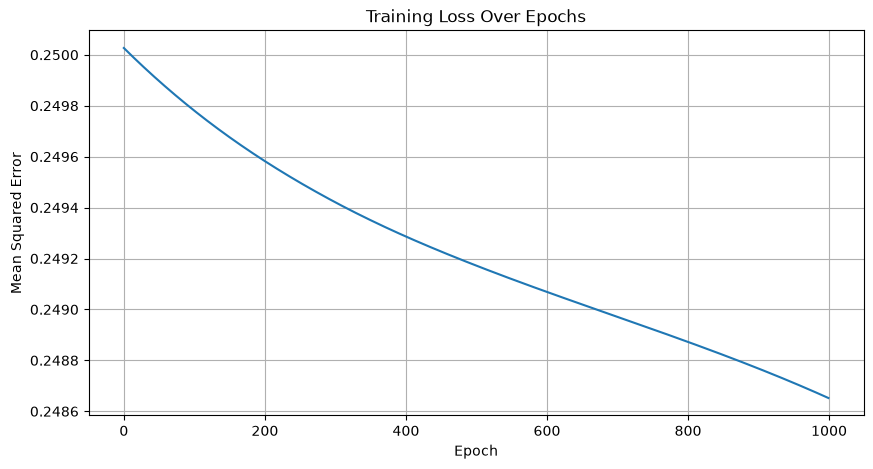

In [113]:
plt.figure(figsize=(10, 5))

plt.plot(loss_history)

plt.title("Training Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.grid(True)
plt.show()

In [114]:
# Generate predictions on training data
train_predictions = network.forward(X_train)

# Convert probabilities into class labels
train_predicted_classes = (train_predictions >= 0.5).astype(int)

# Calculate training accuracy
train_accuracy = np.mean(
    train_predicted_classes == y_train
) * 100

print("Training Accuracy:", train_accuracy, "%")

Training Accuracy: 53.125 %


In [115]:
# Generate predictions
predictions = network.forward(X_train)

# Convert probabilities to classes
predicted_classes = (predictions >= 0.5).astype(int)

# Count predictions
print("Predicted Class 0:", np.sum(predicted_classes == 0))
print("Predicted Class 1:", np.sum(predicted_classes == 1))

# Inspect prediction probabilities
print("\nPrediction statistics:")
print("Minimum:", np.min(predictions))
print("Maximum:", np.max(predictions))
print("Mean:", np.mean(predictions))
print("Standard deviation:", np.std(predictions))

Predicted Class 0: 0
Predicted Class 1: 320

Prediction statistics:
Minimum: 0.5213767224478258
Maximum: 0.5231647289622253
Mean: 0.5223218875232442
Standard deviation: 0.0005762949733773476


In [116]:
# Calculate gradients without updating weights
predictions = network.forward(X_train)
loss = loss_function.forward(predictions, y_train)

gradient = loss_function.backward()
network.backward(gradient)

for i, layer in enumerate(network.layers):
    if isinstance(layer, Linear):
        print(f"\nLinear layer {i}:")
        print("Weight norm:", np.linalg.norm(layer.weights))
        print("Weight gradient norm:", np.linalg.norm(layer.dweights))
        print("Bias gradient norm:", np.linalg.norm(layer.dbias))


Linear layer 0:
Weight norm: 0.06451700921545431
Weight gradient norm: 0.005949856071742289
Bias gradient norm: 0.004304214095002269

Linear layer 2:
Weight norm: 0.06808227709897649
Weight gradient norm: 0.007163810558723948
Bias gradient norm: 0.004435019823098892


In [117]:
# Recreate the network with fresh weights
network = Network([
    Linear(2, 16),
    ReLU(),
    Linear(16, 1),
    Sigmoid()
])

# He initialization for hidden layer
network.layers[0].weights = (
    np.random.randn(2, 16) * np.sqrt(2.0 / 2)
)

# Xavier initialization for output layer
network.layers[2].weights = (
    np.random.randn(16, 1) * np.sqrt(1.0 / 16)
)

print("Improved weight initialization completed!")

Improved weight initialization completed!


In [118]:
epochs = 1000
learning_rate = 0.05

loss_history = []

loss_function = BCELoss()

for epoch in range(epochs):

    predictions = network.forward(X_train)

    loss = loss_function.forward(predictions, y_train)

    gradient = loss_function.backward()

    network.backward(gradient)

    for layer in network.layers:
        if isinstance(layer, Linear):
            layer.weights -= learning_rate * layer.dweights
            layer.bias -= learning_rate * layer.dbias

    loss_history.append(loss)

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss:.6f}")

print("Training completed!")

Epoch 100/1000, Loss: 0.297737
Epoch 200/1000, Loss: 0.264982
Epoch 300/1000, Loss: 0.252523
Epoch 400/1000, Loss: 0.245682
Epoch 500/1000, Loss: 0.241152
Epoch 600/1000, Loss: 0.237698
Epoch 700/1000, Loss: 0.234584
Epoch 800/1000, Loss: 0.231729
Epoch 900/1000, Loss: 0.229075
Epoch 1000/1000, Loss: 0.226587
Training completed!


In [119]:
# Generate predictions on training data
train_predictions = network.forward(X_train)

# Convert probabilities into class labels
train_predicted_classes = (train_predictions >= 0.5).astype(int)

# Calculate training accuracy
train_accuracy = np.mean(
    train_predicted_classes == y_train
) * 100


# Generate predictions on testing data
test_predictions = network.forward(X_test)

# Convert probabilities into class labels
test_predicted_classes = (test_predictions >= 0.5).astype(int)

# Calculate testing accuracy
test_accuracy = np.mean(
    test_predicted_classes == y_test
) * 100


print("Training Accuracy:", train_accuracy, "%")
print("Testing Accuracy:", test_accuracy, "%")

Training Accuracy: 90.0 %
Testing Accuracy: 91.25 %


In [120]:
print("Training predictions:")
print("Class 0:", np.sum(train_predicted_classes == 0))
print("Class 1:", np.sum(train_predicted_classes == 1))

print("\nTesting predictions:")
print("Class 0:", np.sum(test_predicted_classes == 0))
print("Class 1:", np.sum(test_predicted_classes == 1))

Training predictions:
Class 0: 148
Class 1: 172

Testing predictions:
Class 0: 49
Class 1: 31


In [121]:
# Find the minimum and maximum values of our features
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

# Create a grid of coordinates
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Combine grid coordinates into input samples
grid_points = np.c_[xx.ravel(), yy.ravel()]

print("Grid shape:", grid_points.shape)

Grid shape: (90000, 2)


In [122]:
# Predict probabilities for every grid point
grid_predictions = network.forward(grid_points)

# Convert probabilities into classes
grid_classes = (grid_predictions >= 0.5).astype(int)

# Reshape predictions to match the grid
Z = grid_classes.reshape(xx.shape)

print("Decision boundary predictions:", Z.shape)

Decision boundary predictions: (300, 300)


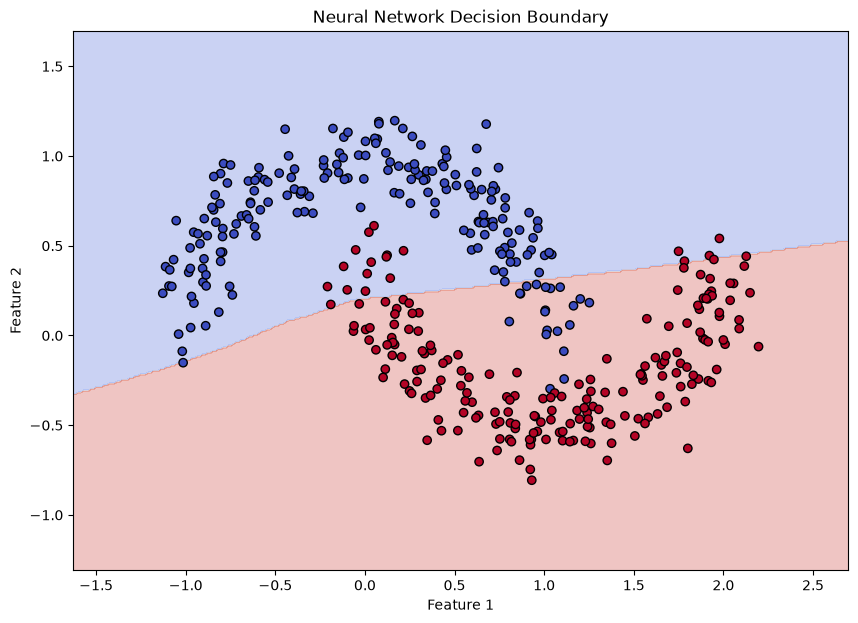

In [123]:
plt.figure(figsize=(10, 7))

# Draw the classification regions
plt.contourf(
    xx, yy, Z,
    alpha=0.3,
    cmap="coolwarm"
)

# Draw the original dataset
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y.ravel(),
    cmap="coolwarm",
    edgecolors="black"
)

plt.title("Neural Network Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [124]:
# Compare predicted classes with actual labels

train_errors = np.sum(
    train_predicted_classes != y_train
)

test_errors = np.sum(
    test_predicted_classes != y_test
)

print("Training errors:", train_errors)
print("Testing errors:", test_errors)

print("Total training samples:", len(y_train))
print("Total testing samples:", len(y_test))

Training errors: 32
Testing errors: 7
Total training samples: 320
Total testing samples: 80


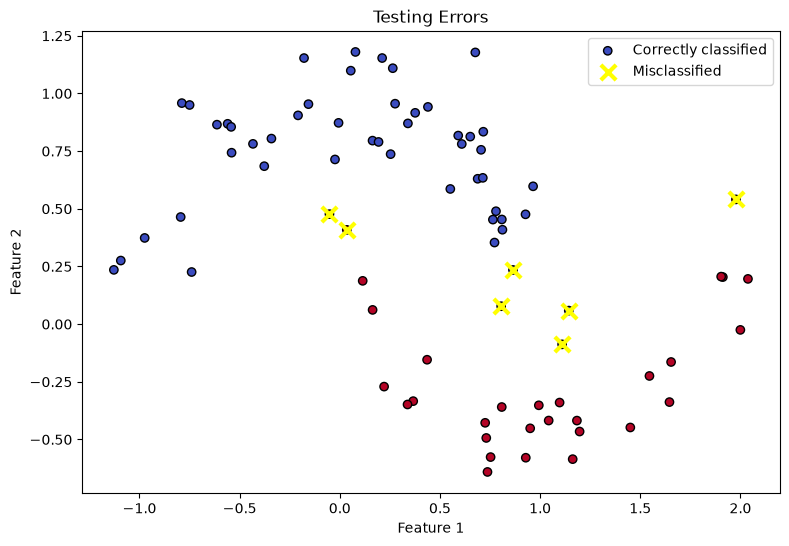

In [125]:
# Find incorrectly classified testing samples
wrong_indices = np.where(
    test_predicted_classes.ravel() != y_test.ravel()
)[0]

# Extract incorrectly classified points
wrong_points = X_test[wrong_indices]

plt.figure(figsize=(9, 6))

# Draw all testing samples
plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test.ravel(),
    cmap="coolwarm",
    edgecolors="black",
    label="Correctly classified"
)

# Highlight incorrect predictions
plt.scatter(
    wrong_points[:, 0],
    wrong_points[:, 1],
    marker="x",
    color="yellow",
    s=120,
    linewidths=3,
    label="Misclassified"
)

plt.title("Testing Errors")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()